# Predicting High-Selling Video Games
**CS363M Machine Learning · UT Austin · Fall 2026**

**Team:** Carlos Olvera, Chris Mathews, Jared Baron Panares, Carlos Galindo

---

### Table of Contents
| Section | What it covers |
|---|---|
| **Introduction** | Problem statement, target definition, dataset description |
| **Setup** | Imports and random seed |
| **Part 1: Initial Data Exploration** | Size, column types, missing values and categories of the raw data |
| **Part 2: Data Cleaning** | Label creation, leakage removal, duplicates, `dropna()`, sanity checks, and exploring the cleaned data against the label |
| **Part 3: Feature Engineering** | Console, platform, publisher, date and critic-score features, plus one-hot encoding |
| **Part 4: Modeling** | Decision Tree, K-Nearest Neighbors and further models: training, tuning and comparison |
| **Part 5: Results & Analysis** | Test-set results, error analysis and interpretation |

Parts 1-3 together form the **Data Exploration & Preprocessing** section.

---

## Introduction

### Problem Statement
Our goal is to predict whether a video game will be a high-selling title based on information about the game.

### Task: Binary Classification
We define a high-selling game as a game that sells at least **1 million copies** globally.

| `label_highselling` | Meaning |
|---|---|
| **1** | High-Selling: ≥ 1 million copies (`total_sales >= 1.0`) |
| **0** | Not High-Selling: < 1 million copies |

We will compare K-Nearest Neighbors and Decision Tree classifiers.

### The Dataset

| | |
|---|---|
| **Source** | [Video Game Sales on Kaggle](https://www.kaggle.com/datasets/yasrebi/video-game-sales) (`VideoGameAnalysis-2024.csv`), scraped from [VGChartz](https://www.vgchartz.com/) |
| **Size** | 64,016 rows × 14 columns |
| **One row** | One game on one console. For example, *Grand Theft Auto V* on PS3, PS4 and X360 is three rows |
| **Years covered** | Release dates from 1971 to 2024. The games we model (after cleaning) were released from 1989 to 2020 |

**Columns**

| Column | Description |
|---|---|
| `img` | Path to the box-art image |
| `title` | Game title |
| `console` | Console the game was released on (e.g. PS4, X360, NS) |
| `genre` | Genre (e.g. Action, Shooter, Sports) |
| `publisher` / `developer` | Company that published / developed the game |
| `critic_score` | Critic score out of 10 |
| `total_sales` | Worldwide sales in **millions of copies** (used only to create the label) |
| `na_sales`, `jp_sales`, `pal_sales`, `other_sales` | Regional sales in millions of copies |
| `release_date` | Release date |
| `last_update` | Date the VGChartz entry was last updated |

---

## Setup: Imports and Random Seed
Every library is imported once here. `SEED = 42` is passed as `random_state=SEED` wherever randomness is involved (splits, CV folds, models), so the results can be reproduced.

In [1]:
# Data handling and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Model selection and preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Models
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    RocCurveDisplay
)

# Random seed used everywhere (random_state=SEED) so results are reproducible
SEED = 42

---

## Part 1: Initial Data Exploration
We start by looking at the **raw** dataset: its size, column types, missing values and how many categories each text column has.

### Loading the Data
We load the CSV into `videogame_df` and keep an untouched copy, `original_df`, for reference.

In [2]:
# Load the raw data and keep an untouched copy
videogame_df = pd.read_csv("VideoGameAnalysis-2024.csv")
original_df = videogame_df.copy()

videogame_df.head()

,img,title,console,genre,publisher,developer,critic_score,total_sales,na_sales,jp_sales,pal_sales,other_sales,release_date,last_update
0,/games/boxart/full_6510540AmericaFrontccc.jpg,Grand Theft Auto V,PS3,Action,Rockstar Games,Rockstar North,9.4,20.32,6.37,0.99,9.85,3.12,2013-09-17,NaN
1,/games/boxart/full_5563178AmericaFrontccc.jpg,Grand Theft Auto V,PS4,Action,Rockstar Games,Rockstar North,9.7,19.39,6.06,0.60,9.71,3.02,2014-11-18,2018-01-03
2,/games/boxart/827563ccc.jpg,Grand Theft Auto: Vice City,PS2,Action,Rockstar Games,Rockstar North,9.6,16.15,8.41,0.47,5.49,1.78,2002-10-28,NaN
3,/games/boxart/full_9218923AmericaFrontccc.jpg,Grand Theft Auto V,X360,Action,Rockstar Games,Rockstar North,NaN,15.86,9.06,0.06,5.33,1.42,2013-09-17,NaN
4,/games/boxart/full_4990510AmericaFrontccc.jpg,Call of Duty: Black Ops 3,PS4,Shooter,Activision,Treyarch,8.1,15.09,6.18,0.41,6.05,2.44,2015-11-06,2018-01-14


### Shape, Column Types and Summary Statistics

In [3]:
# Size and column types
print("Shape:", videogame_df.shape)
videogame_df.info()

# Summary statistics: numeric columns first, then text columns
display(videogame_df.describe().round(2))
display(videogame_df.describe(exclude="number"))

Shape: (64016, 14)
<class 'pandas.DataFrame'>
RangeIndex: 64016 entries, 0 to 64015
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   img           64016 non-null  str    
 1   title         64016 non-null  str    
 2   console       64016 non-null  str    
 3   genre         64016 non-null  str    
 4   publisher     64016 non-null  str    
 5   developer     63999 non-null  str    
 6   critic_score  6678 non-null   float64
 7   total_sales   18922 non-null  float64
 8   na_sales      12637 non-null  float64
 9   jp_sales      6726 non-null   float64
 10  pal_sales     12824 non-null  float64
 11  other_sales   15128 non-null  float64
 12  release_date  56965 non-null  str    
 13  last_update   17879 non-null  str    
dtypes: float64(6), str(8)
memory usage: 6.8 MB


,critic_score,total_sales,na_sales,jp_sales,pal_sales,other_sales
count,6678.00,18922.00,12637.00,6726.00,12824.00,15128.00
mean,7.22,0.35,0.26,0.10,0.15,0.04
std,1.46,0.81,0.49,0.17,0.39,0.13
min,1.00,0.00,0.00,0.00,0.00,0.00
25%,6.40,0.03,0.05,0.02,0.01,0.00
50%,7.50,0.12,0.12,0.04,0.04,0.01
75%,8.30,0.34,0.28,0.12,0.14,0.03
max,10.00,20.32,9.76,2.13,9.85,3.12


,img,title,console,genre,publisher,developer,release_date,last_update
count,64016,64016,64016,64016,64016,63999,56965,17879
unique,56177,39798,81,20,3383,8862,7922,1545
top,/games/boxart/default.jpg,Plants vs. Zombies,PC,Misc,Unknown,Unknown,1994-01-01,2018-01-06
freq,7810,17,12617,9304,8842,4435,515,165


The dataset has 64,016 rows but only 39,798 unique titles, so many games appear on more than one console. Only 18,922 rows have `total_sales` (needed for the label) and only 6,678 have a `critic_score`. "Unknown" is the most common publisher and developer value.

### Missing Values

In [4]:
# Count and percentage of missing values in each column
missing = pd.DataFrame({
    "Missing Count": videogame_df.isnull().sum(),
    "Missing Percent": (videogame_df.isnull().mean() * 100).round(1)
})

missing.sort_values("Missing Percent", ascending=False)

,Missing Count,Missing Percent
critic_score,57338,89.6
jp_sales,57290,89.5
na_sales,51379,80.3
pal_sales,51192,80.0
other_sales,48888,76.4
last_update,46137,72.1
total_sales,45094,70.4
release_date,7051,11.0
img,0,0.0
title,0,0.0


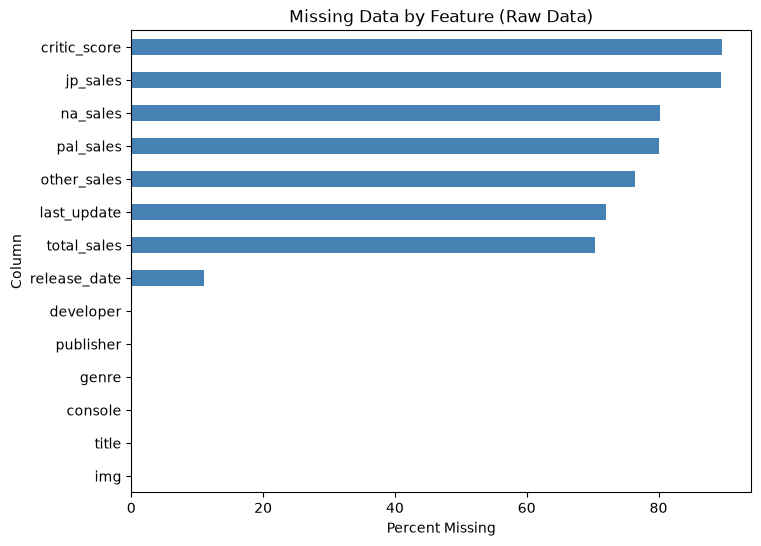

In [5]:
missing["Missing Percent"].sort_values().plot(
    kind="barh",
    figsize=(8, 6),
    color="steelblue"
)

plt.xlabel("Percent Missing")
plt.ylabel("Column")
plt.title("Missing Data by Feature (Raw Data)")
plt.show()

`critic_score` and the sales columns are the most incomplete: about 90% of rows have no critic score and 70% have no `total_sales`. `last_update` is also 72% missing, but it has no predictive meaning and will be dropped. Apart from those, only `release_date` (11%) and `developer` (17 rows) have missing values.

### Number of Categories in the Text Columns

In [6]:
# Number of distinct values in each text column
videogame_df[["genre", "console", "publisher", "developer"]].nunique().to_frame("Unique Values")

,Unique Values
genre,20
console,81
publisher,3383
developer,8862


Genre has only 20 values and console has 81, but publisher (3,383) and developer (8,862) have thousands. One-hot encoding them directly would create thousands of mostly empty columns, so in Part 3 we group the rare publishers into "Other".

---

## Part 2: Data Cleaning
In this part we create the label, remove columns that would leak the answer, remove duplicates and incomplete rows, run sanity checks, and then **explore the cleaned data against the label**.

### Target Variable Creation
We use `total_sales` to determine whether each game was high-selling. Games with missing `total_sales` cannot be labeled, so they are removed.

After the label is created, `total_sales` is removed from the predictors to prevent data leakage: the label comes directly from it.

In [7]:
# Keep only games that have total_sales (the ones we can label)
videogame_df = videogame_df.dropna(subset=["total_sales"])

# 1 = at least 1 million copies sold, 0 = fewer
videogame_df["label_highselling"] = (
    videogame_df["total_sales"] >= 1.0
).astype(int)

### Class Balance of the Labeled Games

In [8]:
# Number and percentage of games in each class
pd.DataFrame({
    "Count": videogame_df["label_highselling"].value_counts(),
    "Percent": (videogame_df["label_highselling"].value_counts(normalize=True) * 100).round(1)
}).rename(index={0: "Not High-Selling (0)", 1: "High-Selling (1)"})

,Count,Percent
label_highselling,,
Not High-Selling (0),17417,92.0
High-Selling (1),1505,8.0


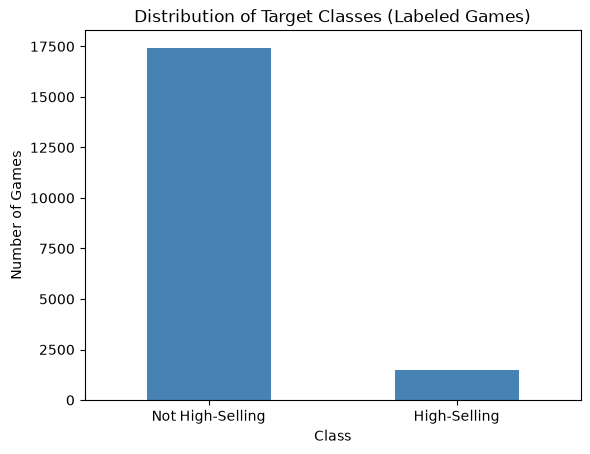

In [9]:
videogame_df["label_highselling"].value_counts().sort_index().plot(
    kind="bar",
    color="steelblue"
)

plt.xticks([0, 1], ["Not High-Selling", "High-Selling"], rotation=0)
plt.xlabel("Class")
plt.ylabel("Number of Games")
plt.title("Distribution of Target Classes (Labeled Games)")
plt.show()

The graph shows a strong class imbalance: about 92% of the labeled games sold under 1 million copies and only 8% are high-sellers. A model that always predicts "Not High-Selling" would already be 92% accurate, so accuracy alone is misleading. We will also report metrics such as precision, recall and F1, and compare against a baseline.

### Dropping Leakage Columns and Saving the Titles
Now that the label exists, we drop `total_sales` and the regional sales columns, which directly reveal the answer, and `img`, which has no predictive meaning. We also save each row's title as `game_titles`, which Part 4 uses to split the data by game.

In [10]:
# Drop the image path and every sales column (they would leak the label)
videogame_df = videogame_df.drop(
    columns=[
        "img",
        "total_sales",
        "na_sales",
        "jp_sales",
        "pal_sales",
        "other_sales"
    ]
)

# Save the title of each row (used later to split train/test by game)
game_titles = original_df.loc[videogame_df.index, "title"]

print("Remaining columns:", videogame_df.columns.tolist())

Remaining columns: ['title', 'console', 'genre', 'publisher', 'developer', 'critic_score', 'release_date', 'last_update', 'label_highselling']


### Missing Values in the Labeled Games
We check the missing values again, now only for the games that have a label.

In [11]:
# Missing values again, now only for the labeled games
missing = pd.DataFrame({
    "Missing Count": videogame_df.isnull().sum(),
    "Missing Percent": (videogame_df.isnull().mean() * 100).round(1)
})

missing.sort_values("Missing Percent", ascending=False)

,Missing Count,Missing Percent
last_update,14903,78.8
critic_score,14796,78.2
release_date,90,0.5
title,0,0.0
console,0,0.0
genre,0,0.0
publisher,0,0.0
developer,4,0.0
label_highselling,0,0.0


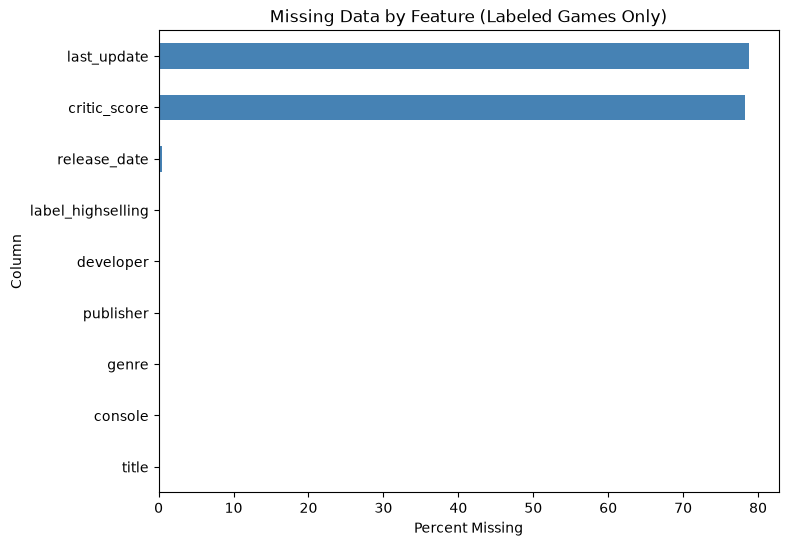

In [12]:
missing["Missing Percent"].sort_values().plot(
    kind="barh",
    figsize=(8, 6),
    color="steelblue"
)

plt.xlabel("Percent Missing")
plt.ylabel("Column")
plt.title("Missing Data by Feature (Labeled Games Only)")
plt.show()

Even among labeled games, 78% have no `critic_score`. `last_update` is also mostly missing, but it is not used as a feature. `release_date` and `developer` are missing for only a handful of rows.

### Selecting the Feature Columns
We keep the title (only for grouping), console, genre, publisher, critic score, release date and the label. `developer` is left out (commented out below); it has 8,862 distinct values in the raw data.

In [13]:
# Columns kept for modeling (title is only used for grouping and is dropped before training)
features = [
    "title",
    "console",
    "genre",
    "publisher",
    #"developer",
    "critic_score",
    "release_date",
    "label_highselling"
]

videogame_df = videogame_df[features]
videogame_df.head()

,title,console,genre,publisher,critic_score,release_date,label_highselling
0,Grand Theft Auto V,PS3,Action,Rockstar Games,9.4,2013-09-17,1
1,Grand Theft Auto V,PS4,Action,Rockstar Games,9.7,2014-11-18,1
2,Grand Theft Auto: Vice City,PS2,Action,Rockstar Games,9.6,2002-10-28,1
3,Grand Theft Auto V,X360,Action,Rockstar Games,NaN,2013-09-17,1
4,Call of Duty: Black Ops 3,PS4,Shooter,Activision,8.1,2015-11-06,1


### Duplicate Records
There were 21 duplicate records (identical in every kept column). We removed them, leaving 0, so no game is counted twice.

In [14]:
# Count duplicates, remove them, then confirm none are left
duplicate_count = videogame_df.duplicated().sum()
videogame_df = videogame_df.drop_duplicates()

print("Duplicate records before:", duplicate_count)
print("Duplicate records after: ", videogame_df.duplicated().sum())

Duplicate records before: 21
Duplicate records after:  0


### Keeping Only Complete Rows (`dropna()`)
We keep only the games that have every feature filled in. Most of the removed rows are missing `critic_score`.

Before dropna(): 18901 games, 8.0% high-selling
After dropna():  4123 games, 18.5% high-selling


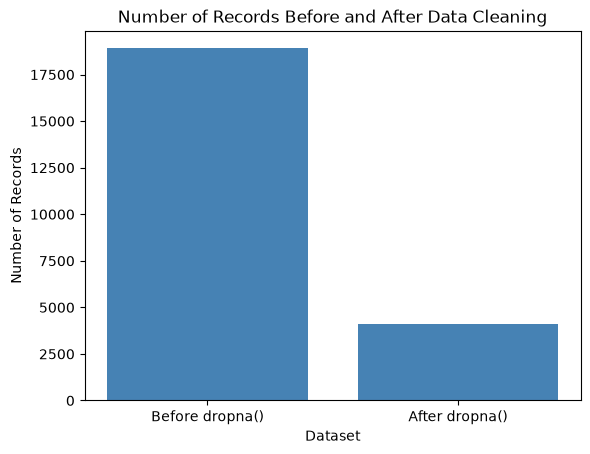

In [15]:
# Size and hit rate before dropping incomplete rows
original_records = len(videogame_df)
hit_rate_before = videogame_df["label_highselling"].mean() * 100

# Remove any row that has at least one missing value
videogame_df = videogame_df.dropna()

# Size and hit rate after
remaining_records = len(videogame_df)
hit_rate_after = videogame_df["label_highselling"].mean() * 100

print(f"Before dropna(): {original_records} games, {hit_rate_before:.1f}% high-selling")
print(f"After dropna():  {remaining_records} games, {hit_rate_after:.1f}% high-selling")

# Compare the number of records before and after
plt.bar(
    ["Before dropna()", "After dropna()"],
    [original_records, remaining_records],
    color="steelblue"
)

plt.title("Number of Records Before and After Data Cleaning")
plt.xlabel("Dataset")
plt.ylabel("Number of Records")
plt.show()

`dropna()` reduces the data from 18,901 to 4,123 games (about 78% of labeled rows removed). The share of high-sellers more than doubles, from 8.0% to 18.5%, so the critic-reviewed games we keep sell better than average. Our results therefore apply to reviewed games.

### Re-aligning the Titles to the Final Rows
`game_titles` was saved before duplicates and incomplete rows were removed, so we keep only the titles of the remaining rows.

In [16]:
# Keep one title per remaining row, in the same order as videogame_df
game_titles = game_titles.loc[videogame_df.index]

print("Rows in videogame_df:", len(videogame_df))
print("Rows in game_titles: ", len(game_titles))
print("Unique titles:       ", game_titles.nunique())

Rows in videogame_df: 4123
Rows in game_titles:  4123
Unique titles:        2873


Both have 4,123 rows, so each title lines up with its game. The 4,123 rows come from 2,873 unique titles.

### Class Balance After Cleaning

,Count,Percent
label_highselling,,
Not High-Selling (0),3361,81.5
High-Selling (1),762,18.5


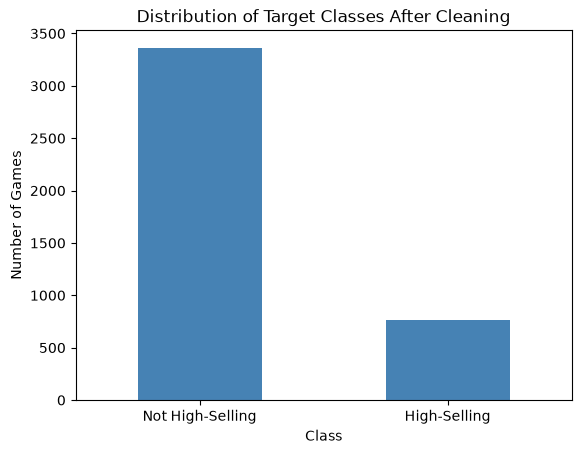

In [17]:
# Number and percentage of games in each class after cleaning
class_counts = videogame_df["label_highselling"].value_counts().sort_index()
display(pd.DataFrame({
    "Count": class_counts,
    "Percent": (class_counts / class_counts.sum() * 100).round(1)
}).rename(index={0: "Not High-Selling (0)", 1: "High-Selling (1)"}))

class_counts.plot(kind="bar", color="steelblue")
plt.xticks([0, 1], ["Not High-Selling", "High-Selling"], rotation=0)
plt.xlabel("Class")
plt.ylabel("Number of Games")
plt.title("Distribution of Target Classes After Cleaning")
plt.show()

After cleaning there are 762 high-sellers out of 4,123 games (18.5%). The data is still imbalanced: always predicting "Not High-Selling" would score 81.5% accuracy. So we will use imbalance-aware metrics and compare every model against a `DummyClassifier`.

### Sanity Checks
We check the text columns for leading or trailing spaces, values that differ only in capitalization, and "Unknown" placeholders. We also confirm that `critic_score` stays within its 0-10 scale.

In [18]:
text_cols = ["console", "genre", "publisher"]

for col in text_cols:
    values = videogame_df[col]
    # Values with leading or trailing spaces
    extra_spaces = (values != values.str.strip()).sum()
    # If lowercasing reduces the number of unique values, some values differ only in capitalization
    case_duplicates = values.nunique() - values.str.lower().nunique()
    # Placeholder values
    unknown = (values.str.lower() == "unknown").sum()
    print(f"{col}: {extra_spaces} values with extra spaces, "
          f"{case_duplicates} capitalization duplicates, {unknown} 'Unknown' rows")

# Critic scores should stay on the 0-10 scale
print()
print("critic_score range:", videogame_df["critic_score"].min(), "to", videogame_df["critic_score"].max())

console: 0 values with extra spaces, 0 capitalization duplicates, 0 'Unknown' rows
genre: 0 values with extra spaces, 0 capitalization duplicates, 0 'Unknown' rows
publisher: 0 values with extra spaces, 0 capitalization duplicates, 7 'Unknown' rows

critic_score range: 1.0 to 10.0


The text columns are clean: there are no extra spaces and no values that differ only in capitalization. Seven games have the publisher "Unknown". That is too few to put it among the top 50 publishers, so in Part 3 these games fall into the "Other" publisher group. `critic_score` ranges from 1.0 to 10.0, which is valid for a 10-point scale.

### Exploring the Cleaned Data
Next we compare the features of the 4,123 cleaned games with the label. In each plot, the **hit rate** is the percentage of games in a group that are high-selling, and the dashed line marks the overall hit rate (18.5%). To avoid misleading 0% or 100% bars from groups of one or two games, the genre, console and publisher hit-rate plots only include groups with at least 20 games. These plots use all the cleaned games, including those that later go into the test set. They guided which features we built, but no label information is put into the features themselves.

#### Hit Rate by Genre

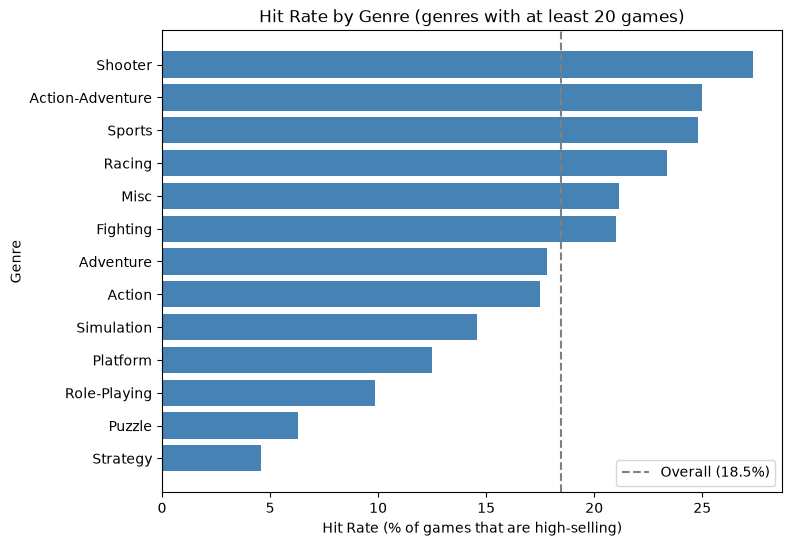

In [19]:
overall_hit_rate = videogame_df["label_highselling"].mean() * 100

# Number of games and hit rate (% high-selling) for each genre
genre_stats = videogame_df.groupby("genre")["label_highselling"].agg(["size", "mean"])
genre_stats["hit_rate"] = genre_stats["mean"] * 100
genre_stats = genre_stats[genre_stats["size"] >= 20].sort_values("hit_rate")

plt.figure(figsize=(8, 6))
plt.barh(genre_stats.index, genre_stats["hit_rate"], color="steelblue")
plt.axvline(overall_hit_rate, color="gray", linestyle="--", label=f"Overall ({overall_hit_rate:.1f}%)")
plt.xlabel("Hit Rate (% of games that are high-selling)")
plt.ylabel("Genre")
plt.title("Hit Rate by Genre (genres with at least 20 games)")
plt.legend()
plt.show()

Genre matters: Shooter, Action-Adventure, Sports and Racing games are high-sellers about 23-27% of the time, while Strategy (5%), Puzzle (6%) and Role-Playing (10%) games rarely are. This makes genre a useful feature.

#### Hit Rate by Console

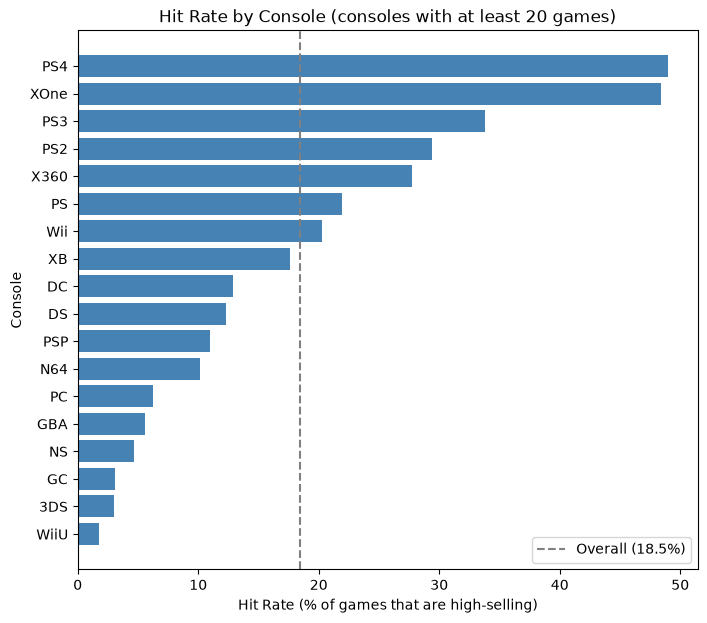

In [20]:
# Number of games and hit rate for each console
console_stats = videogame_df.groupby("console")["label_highselling"].agg(["size", "mean"])
console_stats["hit_rate"] = console_stats["mean"] * 100
console_stats = console_stats[console_stats["size"] >= 20].sort_values("hit_rate")

plt.figure(figsize=(8, 7))
plt.barh(console_stats.index, console_stats["hit_rate"], color="steelblue")
plt.axvline(overall_hit_rate, color="gray", linestyle="--", label=f"Overall ({overall_hit_rate:.1f}%)")
plt.xlabel("Hit Rate (% of games that are high-selling)")
plt.ylabel("Console")
plt.title("Hit Rate by Console (consoles with at least 20 games)")
plt.legend()
plt.show()

Console has an even bigger effect. Games on PS4 and Xbox One are high-sellers almost half the time (49% and 48%), and PS3, PS2 and X360 are also well above average. Nintendo handhelds and home consoles (3DS, GBA, GameCube, Wii U, Switch) and PC are mostly below 6%. In Part 3 this motivates the platform family and handheld features.

#### Number of Games and Hit Rate by Release Year

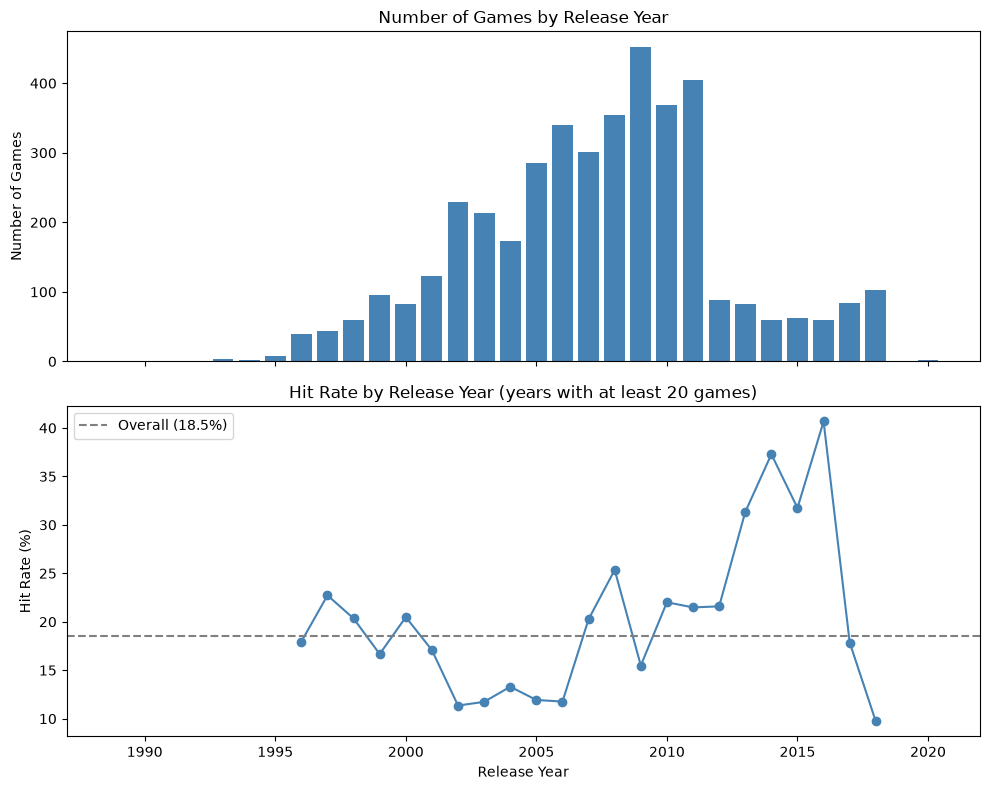

In [21]:
# Release year for exploration only (the date features are created in Part 3)
years = pd.to_datetime(videogame_df["release_date"]).dt.year

year_stats = videogame_df.groupby(years)["label_highselling"].agg(["size", "mean"])
year_stats["hit_rate"] = year_stats["mean"] * 100
year_stats_20 = year_stats[year_stats["size"] >= 20]   # hit rate is noisy for years with very few games

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

axes[0].bar(year_stats.index, year_stats["size"], color="steelblue")
axes[0].set_ylabel("Number of Games")
axes[0].set_title("Number of Games by Release Year")

axes[1].plot(year_stats_20.index, year_stats_20["hit_rate"], marker="o", color="steelblue")
axes[1].axhline(overall_hit_rate, color="gray", linestyle="--", label=f"Overall ({overall_hit_rate:.1f}%)")
axes[1].set_xlabel("Release Year")
axes[1].set_ylabel("Hit Rate (%)")
axes[1].set_title("Hit Rate by Release Year (years with at least 20 games)")
axes[1].legend()

plt.tight_layout()
plt.show()

Most of the cleaned games came out between 2002 and 2011, and there are far fewer after 2011. The hit rate dips to around 12% in 2002-2006, then rises to 31-41% in 2013-2016 before dropping again in 2017-2018. Release year carries some signal, but part of it may just reflect which games the dataset has scores and sales for in each year.

#### Critic Score vs. the Label

Median critic score, not high-selling: 7.1
Median critic score, high-selling:     8.2


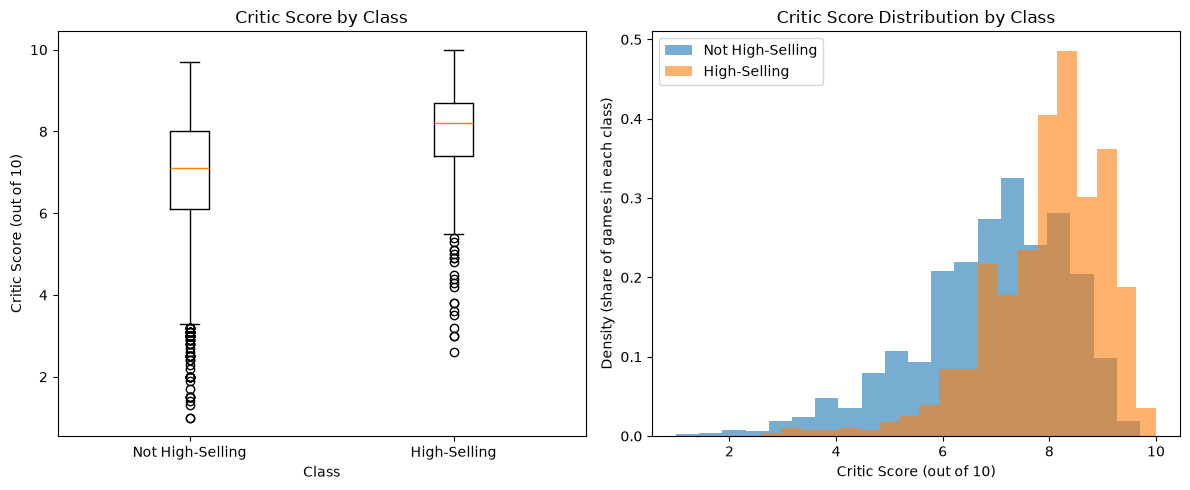

In [22]:
# Split critic scores by class
scores_not_high = videogame_df.loc[videogame_df["label_highselling"] == 0, "critic_score"]
scores_high = videogame_df.loc[videogame_df["label_highselling"] == 1, "critic_score"]

print("Median critic score, not high-selling:", scores_not_high.median())
print("Median critic score, high-selling:    ", scores_high.median())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left: box plot of critic score for each class
axes[0].boxplot([scores_not_high, scores_high])
axes[0].set_xticks([1, 2], ["Not High-Selling", "High-Selling"])
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Critic Score (out of 10)")
axes[0].set_title("Critic Score by Class")

# Right: overlapping histograms (density=True so the two classes are comparable despite different sizes)
axes[1].hist(scores_not_high, bins=20, alpha=0.6, density=True, label="Not High-Selling")
axes[1].hist(scores_high, bins=20, alpha=0.6, density=True, label="High-Selling")
axes[1].set_xlabel("Critic Score (out of 10)")
axes[1].set_ylabel("Density (share of games in each class)")
axes[1].set_title("Critic Score Distribution by Class")
axes[1].legend()

plt.tight_layout()
plt.show()

High-sellers have clearly higher critic scores: the median is 8.2, compared with 7.1 for other games, and most high-sellers score above 7.4. The two distributions still overlap a lot, so critic score alone cannot separate the classes. It is likely one of the strongest single features.

#### Top Publishers by Game Count and by Hit Rate

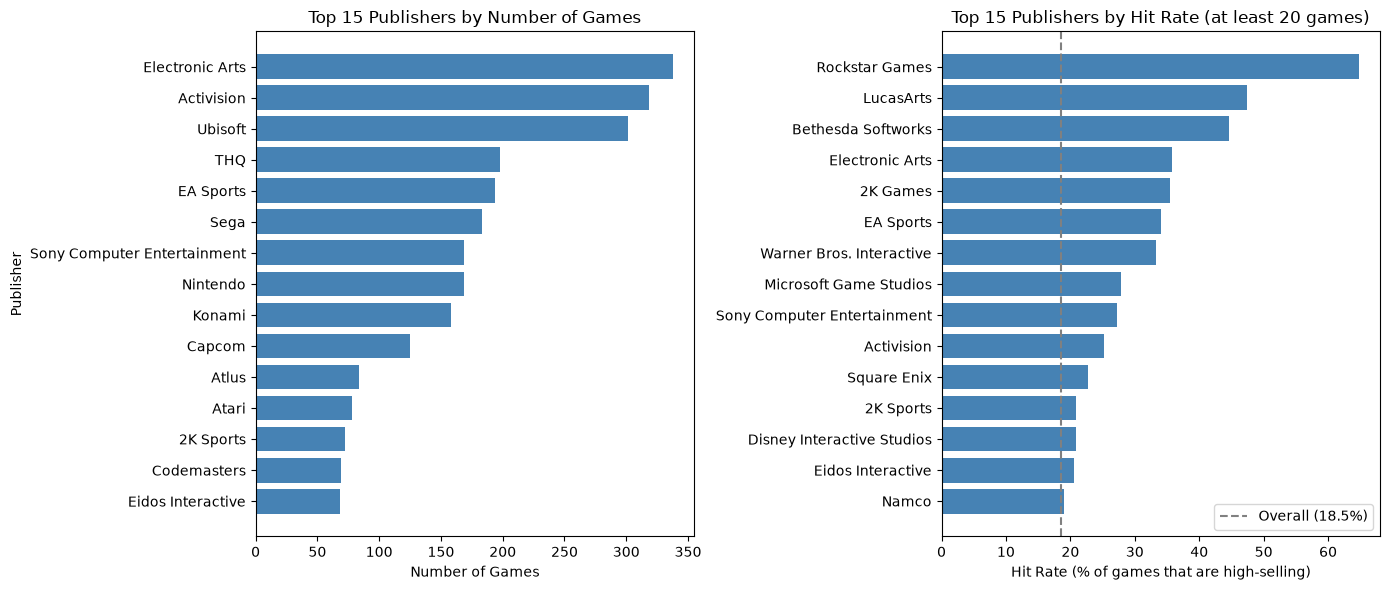

In [23]:
# Number of games and hit rate for each publisher
publisher_stats = videogame_df.groupby("publisher")["label_highselling"].agg(["size", "mean"])
publisher_stats["hit_rate"] = publisher_stats["mean"] * 100

# The 15 biggest publishers, and the 15 highest hit rates among publishers with at least 20 games
top_by_count = publisher_stats.sort_values("size").tail(15)
top_by_hit_rate = publisher_stats[publisher_stats["size"] >= 20].sort_values("hit_rate").tail(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(top_by_count.index, top_by_count["size"], color="steelblue")
axes[0].set_xlabel("Number of Games")
axes[0].set_ylabel("Publisher")
axes[0].set_title("Top 15 Publishers by Number of Games")

axes[1].barh(top_by_hit_rate.index, top_by_hit_rate["hit_rate"], color="steelblue")
axes[1].axvline(overall_hit_rate, color="gray", linestyle="--", label=f"Overall ({overall_hit_rate:.1f}%)")
axes[1].set_xlabel("Hit Rate (% of games that are high-selling)")
axes[1].set_title("Top 15 Publishers by Hit Rate (at least 20 games)")
axes[1].legend()

plt.tight_layout()
plt.show()

The biggest publishers are not always the most successful. Electronic Arts (36%) and EA Sports (34%) publish many games and have high hit rates, while Nintendo (5%) and Atlus (0%) have low hit rates among their *reviewed* games in this dataset. Rockstar Games has the highest hit rate (65%). Publisher therefore carries useful signal, even after grouping rare publishers in Part 3.

#### How Many Games Appear on Several Consoles?

Unique titles: 2873
Titles on more than one console: 708
Rows that share a title with another row: 1958 (47% of rows)


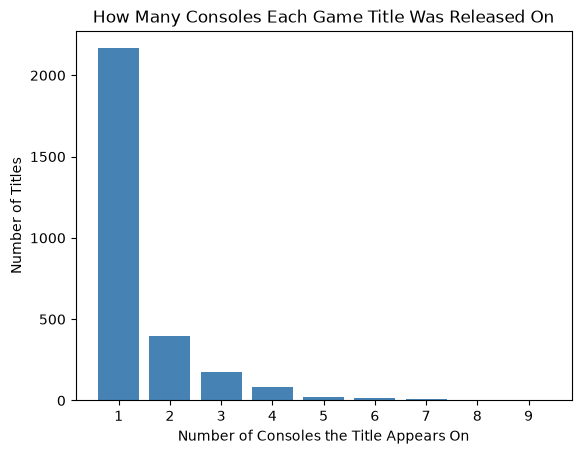

In [24]:
# How many rows (console versions) each title has
rows_per_title = game_titles.value_counts()
titles_by_num_versions = rows_per_title.value_counts().sort_index()

rows_sharing_title = game_titles.duplicated(keep=False).sum()
print("Unique titles:", game_titles.nunique())
print("Titles on more than one console:", (rows_per_title > 1).sum())
print(f"Rows that share a title with another row: {rows_sharing_title} "
      f"({rows_sharing_title / len(game_titles) * 100:.0f}% of rows)")

plt.bar(titles_by_num_versions.index, titles_by_num_versions.values, color="steelblue")
plt.xlabel("Number of Consoles the Title Appears On")
plt.ylabel("Number of Titles")
plt.title("How Many Consoles Each Game Title Was Released On")
plt.xticks(titles_by_num_versions.index)
plt.show()

Most titles (2,165) appear only once, but 708 titles appear on two or more consoles. Together, 1,958 rows (47%) share a title with another row. These versions have nearly identical features and often the same label, so if we split the rows randomly, the same game would land in both the training and the test set and inflate the test score. That is why in Part 4 we split the data **by title** (`game_titles`).

---

## Part 3: Feature Engineering
In this part we create new features from the columns we kept, then turn everything into numbers the models can use.

| Feature | How it is built |
|---|---|
| `platform_family` | Console grouped by maker: PlayStation / Xbox / Nintendo / PC / Other |
| `handheld` | 1 if the console is portable, else 0 |
| `num_platforms` | Number of consoles the title appears on |
| `publisher` | Top 50 publishers kept, the rest grouped into "Other" |
| One-hot columns | `console`, `genre`, `publisher` and `platform_family` |
| `release_year`, `release_month` | Taken from `release_date` |
| `release_quarter`, `holiday_release` | Taken from the month (holiday = October-December) |
| `critic_score_bin` | Critic score grouped into low / mid / high |

None of these features uses the label.

### Console Features: Platform Family and Handheld
`platform_family` groups the 28 consoles by manufacturer; Sega's DC, GEN and SAT go into "Other". `handheld` is 1 for portable consoles (GB, GBC, GBA, DS, 3DS, PSP, PS Vita). The Switch (NS) counts as a home console.

In [25]:
# Map each console to the company that makes it
console_to_family = {
    "PS": "PlayStation", "PS2": "PlayStation", "PS3": "PlayStation", "PS4": "PlayStation",
    "PSP": "PlayStation", "PSV": "PlayStation", "PSN": "PlayStation",
    "XB": "Xbox", "X360": "Xbox", "XOne": "Xbox", "XBL": "Xbox",
    "NES": "Nintendo", "SNES": "Nintendo", "N64": "Nintendo", "GC": "Nintendo",
    "Wii": "Nintendo", "WiiU": "Nintendo", "NS": "Nintendo", "VC": "Nintendo",
    "GB": "Nintendo", "GBC": "Nintendo", "GBA": "Nintendo", "DS": "Nintendo", "3DS": "Nintendo",
    "PC": "PC",
}
# Any console not in the dictionary (Sega's DC, GEN, SAT) becomes "Other"
videogame_df["platform_family"] = videogame_df["console"].map(console_to_family).fillna("Other")

# 1 if the console is a handheld, 0 otherwise
handheld_consoles = ["GB", "GBC", "GBA", "DS", "3DS", "PSP", "PSV"]
videogame_df["handheld"] = videogame_df["console"].isin(handheld_consoles).astype(int)

print(videogame_df["platform_family"].value_counts())
print()
print(videogame_df["handheld"].value_counts())

platform_family
Nintendo       1472
PlayStation    1470
Xbox            767
PC              370
Other            44
Name: count, dtype: int64

handheld
0    3042
1    1081
Name: count, dtype: int64


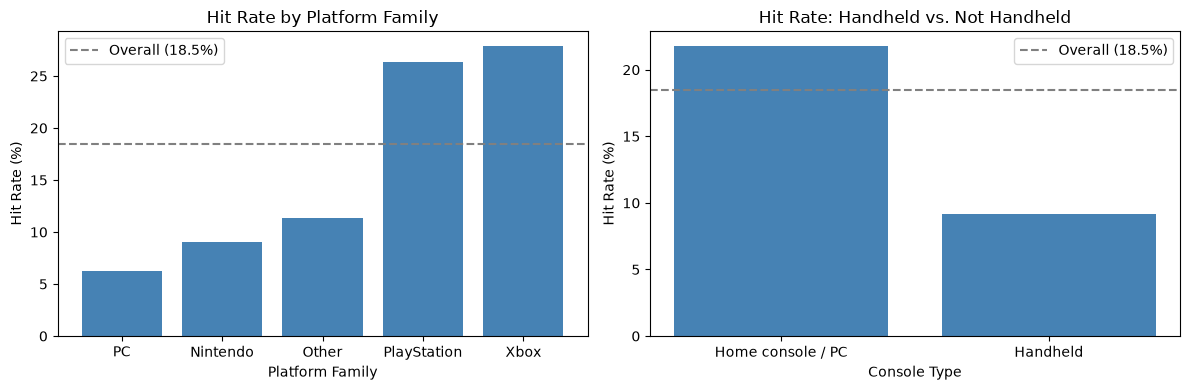

In [26]:
# Hit rate for each platform family and for handheld vs. not handheld
family_hit_rate = videogame_df.groupby("platform_family")["label_highselling"].mean().sort_values() * 100
handheld_hit_rate = videogame_df.groupby("handheld")["label_highselling"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: platform family
axes[0].bar(family_hit_rate.index, family_hit_rate.values, color="steelblue")
axes[0].axhline(overall_hit_rate, color="gray", linestyle="--", label=f"Overall ({overall_hit_rate:.1f}%)")
axes[0].set_xlabel("Platform Family")
axes[0].set_ylabel("Hit Rate (%)")
axes[0].set_title("Hit Rate by Platform Family")
axes[0].legend()

# Right: handheld flag (0 = home console / PC, 1 = handheld)
axes[1].bar(["Home console / PC", "Handheld"], handheld_hit_rate.values, color="steelblue")
axes[1].axhline(overall_hit_rate, color="gray", linestyle="--", label=f"Overall ({overall_hit_rate:.1f}%)")
axes[1].set_xlabel("Console Type")
axes[1].set_ylabel("Hit Rate (%)")
axes[1].set_title("Hit Rate: Handheld vs. Not Handheld")
axes[1].legend()

plt.tight_layout()
plt.show()

Xbox (28%) and PlayStation (26%) games are high-sellers far more often than Nintendo (9%), Sega/"Other" (11%) and PC (6%) games. Handheld games have a hit rate of only 9%, compared with 22% for home console and PC games. Both new features separate the classes.

### Number of Platforms per Title (`num_platforms`)
`num_platforms` counts how many different consoles each title appears on **in our cleaned data** (using `game_titles`). Versions removed during cleaning are not counted. Because Part 4 splits by title, all versions of a game stay on the same side of the split.

num_platforms,1,2,3,4,5,6,7,8,9
size,2171.0,784.0,534.0,336.0,115.0,108.0,49.0,8.0,18.0
hit_rate,10.5,23.7,29.4,31.5,32.2,23.1,36.7,37.5,5.6


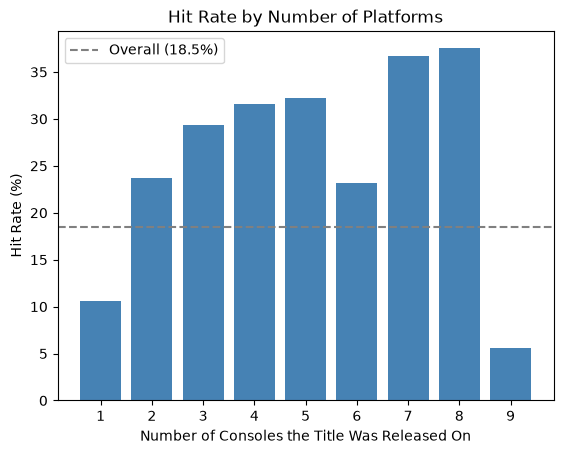

In [27]:
# For each row, count how many different consoles its title appears on
videogame_df["num_platforms"] = videogame_df.groupby(game_titles)["console"].transform("nunique")

# Number of games and hit rate for each platform count
platforms_stats = videogame_df.groupby("num_platforms")["label_highselling"].agg(["size", "mean"])
platforms_stats["hit_rate"] = platforms_stats["mean"] * 100
display(platforms_stats[["size", "hit_rate"]].round(1).T)

plt.bar(platforms_stats.index, platforms_stats["hit_rate"], color="steelblue")
plt.axhline(overall_hit_rate, color="gray", linestyle="--", label=f"Overall ({overall_hit_rate:.1f}%)")
plt.xlabel("Number of Consoles the Title Was Released On")
plt.ylabel("Hit Rate (%)")
plt.title("Hit Rate by Number of Platforms")
plt.xticks(platforms_stats.index)
plt.legend()
plt.show()

Titles released on only one console are high-sellers just 10.5% of the time. Titles on 2-5 consoles reach 24-32%, and titles on 7-8 consoles reach 37%. The groups with 6 or more consoles are small (8-108 rows), so their rates are noisier. The 9-console group, for example, is 18 rows of just two titles. Overall, being released on more platforms goes along with selling better.

### Grouping Rare Publishers and One-Hot Encoding
Publishers outside the 50 most common are replaced with "Other". Then the categorical features (`console`, `genre`, `publisher` and `platform_family`) are one-hot encoded.

In [28]:
categorical_cols = ["console", "genre", "publisher", "platform_family"]

# Number of unique values in each categorical feature
print(videogame_df[categorical_cols].nunique())

# Keep the 50 most frequent publishers and check how many games they cover
fifty_top_publishers = videogame_df["publisher"].value_counts().head(50)
publisher_count = videogame_df["publisher"].isin(fifty_top_publishers.index).sum()
total = videogame_df.shape[0]
print(f"Publishers: {publisher_count}/{total} ({publisher_count / total * 100:.2f}%)")

# Replace publishers outside the top 50 with "Other"
videogame_df["publisher"] = videogame_df["publisher"].where(videogame_df["publisher"].isin(fifty_top_publishers.index), "Other")

# One-hot encode the categorical features (one 0/1 column per category)
videogame_df = pd.get_dummies(videogame_df, columns=categorical_cols, dtype=int)

print("Shape after one-hot encoding:", videogame_df.shape)

console             28
genre               20
publisher          214
platform_family      5
dtype: int64
Publishers: 3622/4123 (87.85%)
Shape after one-hot encoding: (4123, 110)


The top 50 publishers cover 87.85% of the games, and the remaining 12% are now "Other". One-hot encoding turns the 4 categorical columns into 104 numeric 0/1 columns (28 console + 20 genre + 51 publisher + 5 platform family).

### Date Features: Month and Year
`release_date` is converted to a datetime and split into `release_month` and `release_year`; the raw date is then dropped. `critic_score` stays numeric as it is (a binned version is added below).

In [29]:
# Convert release_date to datetime
videogame_df["release_date"] = pd.to_datetime(videogame_df["release_date"])

# Split it into month and year
videogame_df["release_month"] = videogame_df["release_date"].dt.month
videogame_df["release_year"] = videogame_df["release_date"].dt.year

# Drop the original release_date column
videogame_df = videogame_df.drop(columns=["release_date"])

videogame_df[["release_month", "release_year"]].describe().loc[["min", "max"]]

,release_month,release_year
min,1.0,1989.0
max,12.0,2020.0


### Date Features: Quarter and Holiday Flag
From the month we derive `release_quarter` (1-4) and `holiday_release`, which is 1 if the game came out in October, November or December.

holiday_release
0    14.8
1    24.5
Name: label_highselling, dtype: float64


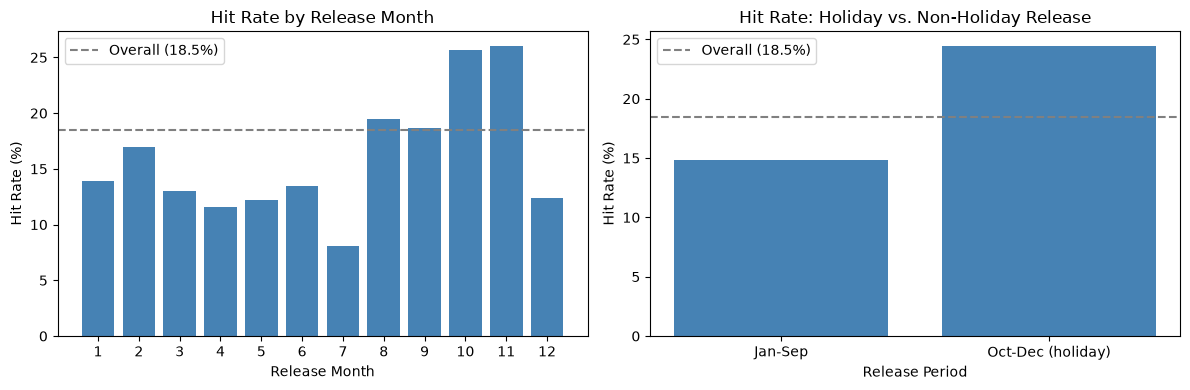

In [30]:
# Quarter of the year: months 1-3 -> 1, 4-6 -> 2, 7-9 -> 3, 10-12 -> 4
videogame_df["release_quarter"] = (videogame_df["release_month"] - 1) // 3 + 1

# 1 if released in October, November or December (holiday season)
videogame_df["holiday_release"] = videogame_df["release_month"].isin([10, 11, 12]).astype(int)

# Hit rate by month and by holiday flag
month_hit_rate = videogame_df.groupby("release_month")["label_highselling"].mean() * 100
holiday_hit_rate = videogame_df.groupby("holiday_release")["label_highselling"].mean() * 100
print(holiday_hit_rate.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: hit rate for each release month
axes[0].bar(month_hit_rate.index, month_hit_rate.values, color="steelblue")
axes[0].axhline(overall_hit_rate, color="gray", linestyle="--", label=f"Overall ({overall_hit_rate:.1f}%)")
axes[0].set_xticks(range(1, 13))
axes[0].set_xlabel("Release Month")
axes[0].set_ylabel("Hit Rate (%)")
axes[0].set_title("Hit Rate by Release Month")
axes[0].legend()

# Right: holiday vs. non-holiday releases
axes[1].bar(["Jan-Sep", "Oct-Dec (holiday)"], holiday_hit_rate.values, color="steelblue")
axes[1].axhline(overall_hit_rate, color="gray", linestyle="--", label=f"Overall ({overall_hit_rate:.1f}%)")
axes[1].set_xlabel("Release Period")
axes[1].set_ylabel("Hit Rate (%)")
axes[1].set_title("Hit Rate: Holiday vs. Non-Holiday Release")
axes[1].legend()

plt.tight_layout()
plt.show()

Games released in October-December are high-sellers 24.5% of the time, compared with 14.8% for the rest of the year. October and November drive the effect, while December has fewer releases and a below-average hit rate.

### Critic Score Bins (`critic_score_bin`)
As suggested in our proposal, critic scores are grouped into categories: 0 = low (6.0 or below), 1 = mid (above 6.0 up to 8.0), 2 = high (above 8.0). The original `critic_score` is kept as well.

,size,hit_rate
critic_score_bin,,
0,873,4.9
1,2107,14.4
2,1143,36.3


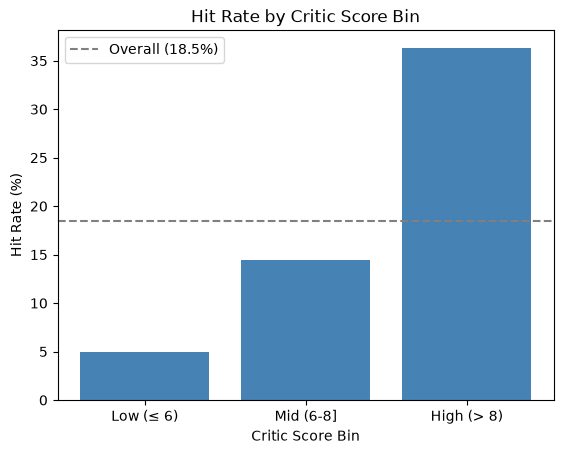

In [31]:
# Bins: (0, 6] -> 0 (low), (6, 8] -> 1 (mid), (8, 10] -> 2 (high)
videogame_df["critic_score_bin"] = pd.cut(
    videogame_df["critic_score"],
    bins=[0, 6, 8, 10],
    labels=[0, 1, 2]
).astype(int)

# Number of games and hit rate in each bin
bin_stats = videogame_df.groupby("critic_score_bin")["label_highselling"].agg(["size", "mean"])
bin_stats["hit_rate"] = bin_stats["mean"] * 100
display(bin_stats[["size", "hit_rate"]].round(1))

plt.bar(["Low (≤ 6)", "Mid (6-8]", "High (> 8)"], bin_stats["hit_rate"], color="steelblue")
plt.axhline(overall_hit_rate, color="gray", linestyle="--", label=f"Overall ({overall_hit_rate:.1f}%)")
plt.xlabel("Critic Score Bin")
plt.ylabel("Hit Rate (%)")
plt.title("Hit Rate by Critic Score Bin")
plt.legend()
plt.show()

The hit rate rises steadily across the bins: 4.9% for low scores, 14.4% for mid scores and 36.3% for high scores, matching the box plot in Part 2.

### Label-Based Features
We did **not** create any features from the label (such as a publisher's hit rate). Every Part 3 feature comes only from the console, genre, publisher, title, critic score and release date. Any label-based feature added later must be computed on the training data only.

### Engineered Features Overview
The final table: `title` is kept only so Part 4 can drop it before training, and every other column is numeric.

In [32]:
# The new (non-one-hot) features plus the platform family one-hot columns
engineered_cols = [
    "critic_score", "critic_score_bin",
    "release_year", "release_month", "release_quarter", "holiday_release",
    "handheld", "num_platforms",
]
platform_family_cols = [col for col in videogame_df.columns if col.startswith("platform_family_")]

# Confirm the final size and that only title is non-numeric
print("Final shape:", videogame_df.shape)
print("Non-numeric columns:", list(videogame_df.select_dtypes(exclude="number").columns))

videogame_df[["title"] + engineered_cols + platform_family_cols + ["label_highselling"]].head()

Final shape: (4123, 114)
Non-numeric columns: ['title']


,title,critic_score,critic_score_bin,release_year,release_month,release_quarter,holiday_release,handheld,num_platforms,platform_family_Nintendo,platform_family_Other,platform_family_PC,platform_family_PlayStation,platform_family_Xbox,label_highselling
0,Grand Theft Auto V,9.4,2,2013,9,3,0,0,3,0,0,0,1,0,1
1,Grand Theft Auto V,9.7,2,2014,11,4,1,0,3,0,0,0,1,0,1
2,Grand Theft Auto: Vice City,9.6,2,2002,10,4,1,0,2,0,0,0,1,0,1
4,Call of Duty: Black Ops 3,8.1,2,2015,11,4,1,0,1,0,0,0,1,0,1
5,Call of Duty: Modern Warfare 3,8.7,2,2011,11,4,1,0,4,0,0,0,0,1,1


**Summary of Part 3:** we now have 4,123 games and 114 columns: the label, `title` (dropped before training) and 112 numeric features.

| Group | Columns |
|---|---|
| One-hot encoded | console (28), genre (20), publisher (51), platform family (5) |
| Numeric / flags | `critic_score`, `critic_score_bin`, `release_year`, `release_month`, `release_quarter`, `holiday_release`, `handheld`, `num_platforms` |

The plots above show that critic score, console and platform family, number of platforms, and holiday timing each separate high-sellers from the rest.

## Part 4: Algorithm Selection
The first algorithm we chose was Decision Trees.

In [33]:
# Title must be dropped for training
videogame_labels = videogame_df['label_highselling']
videogame_features = videogame_df.drop(columns=['label_highselling','title'])

# We use the 80-20 split to separate our data into training and test sets.
X_train, X_test, y_train, y_test = train_test_split(videogame_features, videogame_labels, test_size=0.2, train_size=0.8)

# Verify the number of records in each.
print("Number of Training Records: " + str(len(X_train)))
print("Number of Test Records: " + str(len(X_test)))

# We can use the sci-kit learn DecisionTreeClassifier. We can then keep track of its accuracy.
decision_tree = DecisionTreeClassifier(criterion='entropy', max_depth=10)
decision_tree.fit(X_train, y_train)

prediction = decision_tree.predict(X_test)
accuracy = accuracy_score(y_test, prediction)
print("Accuracy Score: " + str(accuracy))

Number of Training Records: 3298
Number of Test Records: 825
Accuracy Score: 0.8654545454545455


Decision Tress have two hyperparameters that can be tuned to improve accuracy. These are the max depth of the tree (max_depth) and the minimum number of samples required to be at a leaf node (min_samples_leaf). First, we'll adjust the max_depth of the tree to determine the best depth from 1 to 21. We've set that range to make the training plateau easier to observe.

Depth 1- Training Accuracy: 0.8147362037598544
Depth 1- Training Accuracy: 0.816969696969697
Depth 2- Training Accuracy: 0.8147362037598544
Depth 2- Training Accuracy: 0.816969696969697
Depth 3- Training Accuracy: 0.8268647665251667
Depth 3- Training Accuracy: 0.8278787878787879
Depth 4- Training Accuracy: 0.8435415403274712
Depth 4- Training Accuracy: 0.8581818181818182
Depth 5- Training Accuracy: 0.8486961795027289
Depth 5- Training Accuracy: 0.8581818181818182
Depth 6- Training Accuracy: 0.8602183141297757
Depth 6- Training Accuracy: 0.8569696969696969
Depth 7- Training Accuracy: 0.8720436628259551
Depth 7- Training Accuracy: 0.8618181818181818


Depth 8- Training Accuracy: 0.8820497271073378
Depth 8- Training Accuracy: 0.8472727272727273
Depth 9- Training Accuracy: 0.8932686476652517
Depth 9- Training Accuracy: 0.8666666666666667
Depth 10- Training Accuracy: 0.9063068526379624
Depth 10- Training Accuracy: 0.8593939393939394


Depth 11- Training Accuracy: 0.9248029108550637
Depth 11- Training Accuracy: 0.8569696969696969
Depth 12- Training Accuracy: 0.9393571861734384
Depth 12- Training Accuracy: 0.863030303030303
Depth 13- Training Accuracy: 0.9499696785930867
Depth 13- Training Accuracy: 0.8618181818181818


Depth 14- Training Accuracy: 0.959066100667071
Depth 14- Training Accuracy: 0.863030303030303
Depth 15- Training Accuracy: 0.968465736810188
Depth 15- Training Accuracy: 0.8557575757575757
Depth 16- Training Accuracy: 0.9736203759854457
Depth 16- Training Accuracy: 0.8533333333333334
Depth 17- Training Accuracy: 0.9787750151607034
Depth 17- Training Accuracy: 0.8533333333333334
Depth 18- Training Accuracy: 0.9827167980594299
Depth 18- Training Accuracy: 0.8642424242424243
Depth 19- Training Accuracy: 0.9887810794420862
Depth 19- Training Accuracy: 0.8642424242424243
Depth 20- Training Accuracy: 0.9915100060642814
Depth 20- Training Accuracy: 0.8654545454545455


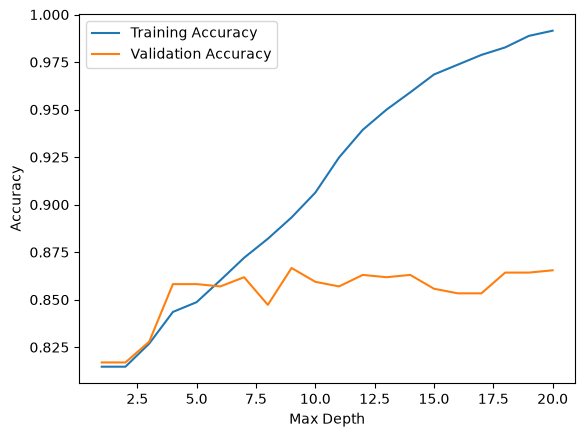

In [34]:
training_accuracies = []
testing_accuracies = []

for depth in range(1, 21):
    decision_tree = DecisionTreeClassifier(criterion='entropy', max_depth=depth)
    decision_tree.fit(X_train, y_train)

    training_prediction = decision_tree.predict(X_train)
    training_accuracy = accuracy_score(y_train, training_prediction)
    training_accuracies.append(training_accuracy)

    testing_prediction = decision_tree.predict(X_test)
    testing_accuracy = accuracy_score(y_test, testing_prediction)
    testing_accuracies.append(testing_accuracy)

    print("Depth " + str(depth) + "- Training Accuracy: " + str(training_accuracy))
    print("Depth " + str(depth) + "- Training Accuracy: " + str(testing_accuracy))

# We can see a visual of the accuracies here. We want to pick a validation accuracy that's highest
# while the depth is kept low.
plt.plot(range(1, 21), training_accuracies, label='Training Accuracy')
plt.plot(range(1, 21), testing_accuracies, label='Validation Accuracy')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.legend()

Depth 20- Training Accuracy: 0.906913280776228
Depth 20- Training Accuracy: 0.8642424242424243
Depth 20- Training Accuracy: 0.8838690115221346
Depth 20- Training Accuracy: 0.863030303030303
Depth 20- Training Accuracy: 0.8765918738629472
Depth 20- Training Accuracy: 0.8654545454545455
Depth 20- Training Accuracy: 0.865979381443299
Depth 20- Training Accuracy: 0.8606060606060606
Depth 20- Training Accuracy: 0.8489993935718617
Depth 20- Training Accuracy: 0.850909090909091
Depth 20- Training Accuracy: 0.8405093996361431
Depth 20- Training Accuracy: 0.8533333333333334


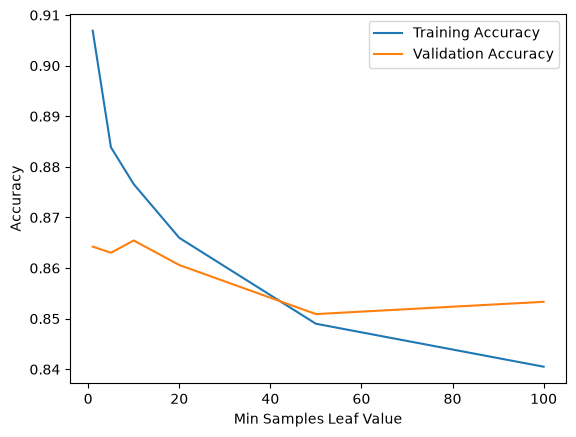

In [35]:
# We pick a set of leaf values that increases exponentially as smaller hyperparameter values are more 
# are more impactful for this value
min_samples_leaves = [1, 5, 10, 20, 50, 100] 
training_accuracies = []
testing_accuracies = []

for n in min_samples_leaves:
    decision_tree = DecisionTreeClassifier(criterion='entropy', max_depth=10, min_samples_leaf=n)
    decision_tree.fit(X_train, y_train)

    training_prediction = decision_tree.predict(X_train)
    training_accuracy = accuracy_score(y_train, training_prediction)
    training_accuracies.append(training_accuracy)

    testing_prediction = decision_tree.predict(X_test)
    testing_accuracy = accuracy_score(y_test, testing_prediction)
    testing_accuracies.append(testing_accuracy)

    print("Depth " + str(depth) + "- Training Accuracy: " + str(training_accuracy))
    print("Depth " + str(depth) + "- Training Accuracy: " + str(testing_accuracy))

# We can see a visual of the accuracies here. We want to pick a validation accuracy that's highest
# while the depth is kept low.
plt.plot(min_samples_leaves, training_accuracies, label='Training Accuracy')
plt.plot(min_samples_leaves, testing_accuracies, label='Validation Accuracy')
plt.xlabel('Min Samples Leaf Value')
plt.ylabel('Accuracy')
plt.legend()

We decided to pick a max_depth of [blank] and min_samples_leaf of [blank]

In [36]:
# Note adjust this when we decide which hyperparameters to pick
decision_tree = DecisionTreeClassifier(criterion='entropy', max_depth=10)
cross = cross_val_score(decision_tree, videogame_features, videogame_labels, cv=5)

print("Mean CV Accuracy: " + str(cross.mean()))
print("Standard Deviation: " + str(cross.std()))

Mean CV Accuracy: 0.7984548396587232
Standard Deviation: 0.039235352295244476
